# A corrected motion-data feasibility check
Ning Yang

I first ran a small fixed-feature head and obtained poor results. The adapter was wrong: it clipped every value in the fourth binary column and collapsed four features. It also concatenated available frames across missing index slots. I retained those results, fixed the representation, and ran this separate development study.

This notebook reviews **record-level activity recognition**, not the earlier window task. A higher score here cannot isolate the effect of the adapter correction. It is an independent supplement to the frozen CSDP toy appendix, not a replacement or an SNN-method result.

## What changed in the input

The five binary columns stay anonymous; the authoritative sources do not establish their serialized physical units. I apply the same fixed monotone transform, $2\arctan(v)/\pi$, to every column. Each recording retains slots 1–297 and an explicit payload-availability mask. Consecutive blocks of ten slots produce 30 steps, with the last block containing seven slots. Missing slots are not compressed away.

The source archive is already filtered and aggregated. Index slots are not validated timestamps; this is an offline benchmark, with no claim of zero-look-ahead acquisition. `DATA_VERIFICATION.md` records the source evidence.

In [1]:
from src.corrected_review import (
    show_audit, show_references, show_noise, plot_curves, show_validation
)
show_audit()

Recordings: 646 training / 215 development; subjects: 24 / 8
Held-out payloads opened: 0
Absent index slots: 47715 ; empty payloads: 0
Constant pooled training features: []


## Does this task contain learnable signal?

I used fixed-feature logistic regression, ExtraTrees and a small GRU as non-private diagnostic references. The GRU has 48 hidden units and runs for 40 epochs; the endpoint is fixed, not the best observed epoch. All three seeds are reported. Logistic regression is deterministic here, so its repeated fits are not independent trials.

These model families use different budgets: the table is a learnability check, not an algorithm superiority claim. Evaluation gives each subject equal total confusion weight, then averages F1 over all 27 classes. A mask-only logistic control checks whether the availability pattern alone accounts for the results.

In [2]:
show_references()

Method                       Dev macro-F1, %      Train macro-F1, %
fixed_logistic                54.08 [54.08, 54.08]      58.51
fixed_extra_trees             69.28 [68.85, 69.71]     100.00
gru                           56.80 [53.81, 61.33]      65.89
mask_only_logistic             4.04 [4.04, 4.04]      24.58
Brackets: seed range, not confidence intervals. Logistic repeats are deterministic.


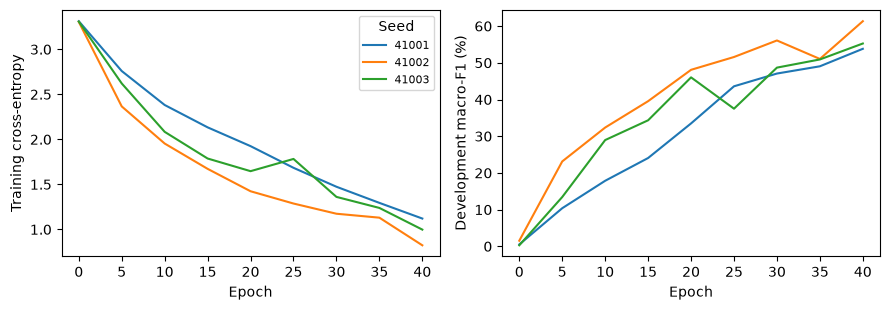

In [3]:
figure = plot_curves()

*GRU training loss and development macro-F1, all three seeds; no best-epoch selection.*

The fixed-feature and GRU references exceed the prespecified 20% development gate, while the mask-only control reaches 4.04%. This supports a useful offline baseline, though acquisition artifacts and temporal generalisation still need investigation. ExtraTrees fits the training set perfectly; its development performance does not establish robustness on unseen populations. The GRU does not outperform the tree reference.

## The noise comparison did not work

For this comparison I use the fixed 108-dimensional representation, **not the trained GRU encoder**. At each round I average recording gradients within each person, clip the complete weight-and-bias update at norm 1, sum sampled subject updates, add Gaussian noise and divide by the fixed normalizer 8. Every method uses the same initialization and subject-selection masks. Empty selections would still receive noise.

The 300-round mechanism is calibrated to $\varepsilon\leq3$, $\delta=10^{-5}$ under add/remove-one subject adjacency, with Poisson rate $1/3$ and noise multiplier 8.738442. Public fixed seeds make the following **utility simulations, not privacy-protected releases**. The bound describes one hypothetical secret-randomness mechanism; it does not cover all runs, development metrics or a privately trained encoder.

In [4]:
show_noise()

Seed      Unclipped   Clipped   Noise simulation   Difference, pp
42001        45.59      45.59          2.12           -43.47
42002        48.41      48.41          1.30           -47.11
42003        47.27      47.27          2.24           -45.02
42004        45.83      45.83          2.29           -43.54
42005        45.99      45.99          1.27           -44.72
42006        46.26      46.26          1.10           -45.16
42007        48.22      48.22          1.86           -46.36
42008        45.92      45.92          2.56           -43.36
42009        45.08      45.08          2.53           -42.55
42010        46.17      46.17          1.60           -44.57
Mean difference: -44.59 pp; paired t interval: [-45.60, -43.57] pp
Interval describes optimization-seed variation, not new-subject uncertainty.


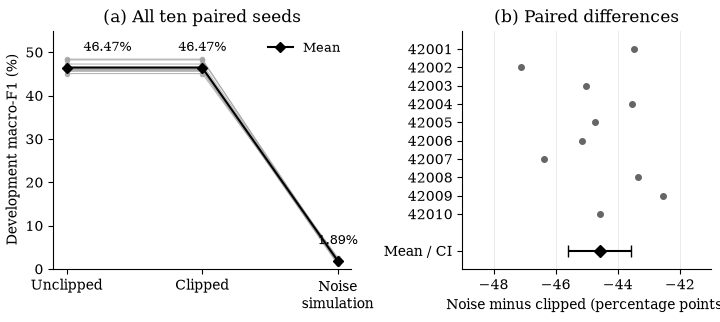

In [5]:
from src.appendix_visuals import plot_noise_pairs
figure = plot_noise_pairs()


*All ten paired seeds. Unclipped and clipped endpoints coincide. The diamond and interval in panel (b) are the mean paired difference and its t95% interval over optimization seeds, not future subjects. Public-randomness utility simulation; not a protected release.*

The noiseless head averages 46.47% macro-F1; the noisy simulation averages 1.89%. The mean difference is −44.59 percentage points, with an optimization-seed interval [−45.60, −43.57]. These are development results from eight people, not a population-level confidence statement.

Clipping is inactive in the noiseless controls, but roughly 89.84–96.62% of selected updates are clipped in the noisy runs. Noise changes the optimization trajectory, so I cannot attribute the loss to a single isolated cause. This configuration fails the utility check. It does not prove that subject-level privacy is impossible, or that local learning solves the problem.

## Checks and remaining scope

Sixteen tests cover the original and corrected code. A separate implementation retrained all 30 noise-comparison endpoints and matched the saved metrics; all 12 reference fits were also repeated on the same machine. The notebook reads the saved results and plots them; full experiment reruns are documented in `REPRODUCE.md`.

In [6]:
show_validation()

validation.json : {'passed': True, 'reference_runs': 12, 'noise_runs': 30, 'curve_rows': 9030, 'independently_retrained_noise_endpoints': 30, 'max_endpoint_error': 0.0, 'source_hashes_verified': True, 'test_payloads_opened': 0, 'scope': 'Same-machine development reproducibility; not independent subject confirmation'}
reference_reproduction.json : {'passed': True, 'runs_repeated': 12, 'max_numeric_difference': 0.0, 'scope': 'Same machine, same installed environment; elapsed times excluded'}


I have not opened the eight test-subject payloads. This study does not establish an original SNN learning rule, privacy utility for a trained SNN, energy savings, fall detection or clinical benefit. The next substantive study would need a separately fixed protocol for a compact local-learning SNN and a defensible clipping/utility design, followed by held-out subject evaluation. I would not present the current noise result as successful feasibility evidence.

### Sources
- Yang et al., *MM-Fi: Multi-Modal Non-Intrusive 4D Human Dataset for Versatile Wireless Sensing*, NeurIPS Datasets and Benchmarks, 2023. [Dataset page](https://ntu-aiot-lab.github.io/mm-fi); [official toolbox](https://github.com/ybhbingo/MMFi_dataset).
- [Official MM-Fi dataset notice](https://docs.google.com/document/d/1484VK1Lw7JWQ6FHqIEypx0sZ3xzw2MeG7QhRvA5ihoc/edit) describes the additional filtered-and-aggregated radar archive. Source checks and field uncertainty are summarised in `DATA_VERIFICATION.md`.
